# Aprendendo uma Função Complexa $z = f(x, y)$ com Redes Neurais em PyTorch

Este notebook constrói, do início ao fim, um pipeline completo de treinamento de uma rede neural densa para **aproximar uma função matemática complexa de duas variáveis**, e em seguida realiza uma **série de experimentos controlados** para observar como diferentes componentes da rede afetam o resultado final.

**Estrutura do notebook:**

1. Definição da função complexa $z = f(x, y)$
2. Geração do dataset (com ruído gaussiano ajustável)
3. Conversão para tensores PyTorch
4. Construção e treinamento do modelo baseline
5. Avaliação e visualização dos resultados (métricas + gráficos comparativos)
6. Framework genérico para experimentos
7. **Experimento A** — Arquitetura das camadas ocultas
8. **Experimento B** — Funções de ativação
9. **Experimento C** — Função de perda (*loss function*)
10. **Experimento D** — Taxa de aprendizado (*learning rate*)
11. **Experimento E** — Otimizador
12. **Experimento F** — Regularização (Dropout)
13. **Experimento G** — Nível de ruído no dataset
14. Consolidação final e conclusões

> O notebook funciona tanto localmente quanto no Google Colab, com ou sem GPU — o dispositivo (`cpu`/`cuda`) é detectado automaticamente.

## 0. Setup

Importamos as bibliotecas necessárias e fixamos as sementes aleatórias para reprodutibilidade. O dispositivo de execução (`cuda` ou `cpu`) é detectado automaticamente — o notebook funciona igualmente bem em um Colab com GPU ou em uma máquina local sem GPU.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# Reprodutibilidade
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detecção automática de dispositivo (funciona com ou sem GPU, local ou Colab)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo em uso: {device}")
print(f"Versão do PyTorch: {torch.__version__}")

Dispositivo em uso: cpu
Versão do PyTorch: 2.13.0+cpu


## 1. A Função Complexa $z = f(x, y)$

Vamos usar uma função não linear de duas variáveis, que combina termos oscilatórios (seno e cosseno) com um termo de interação entre $x$ e $y$ — complexa o suficiente para não ser trivialmente aproximada por um modelo linear, mas simples o bastante para visualizarmos com clareza:

$$f(x, y) = \sin(x)\cdot\cos(y) + 0{,}1 \cdot x \cdot y$$

Na prática, quando treinamos um modelo de IA, não conhecemos a função geradora dos dados — é justamente isso que o modelo deve aprender a partir de exemplos. Usamos essa função conhecida propositalmente para podermos comparar a previsão da rede com a "verdade" exata.

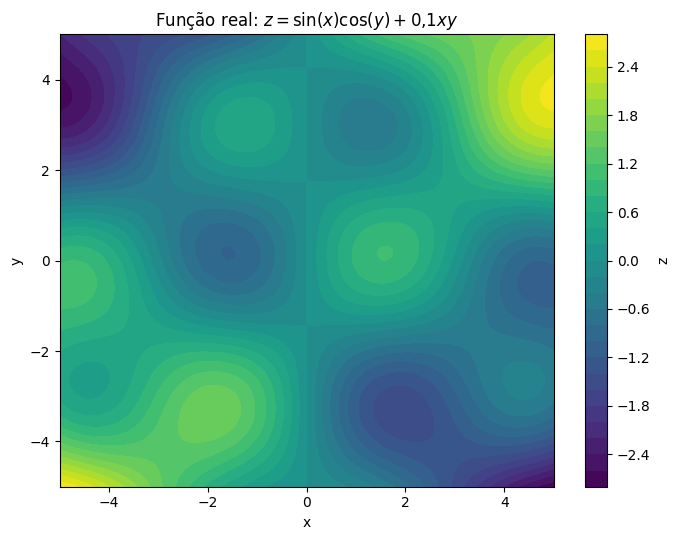

In [2]:
def complex_function(x, y):
    """Função complexa e não linear de duas variáveis que a rede neural deverá aprender."""
    return np.sin(x) * np.cos(y) + 0.1 * x * y

# Grid denso para visualizar a função real
DOMINIO = (-5, 5)
grid_1d = np.linspace(DOMINIO[0], DOMINIO[1], 150)
GRID_X, GRID_Y = np.meshgrid(grid_1d, grid_1d)
GRID_Z_REAL = complex_function(GRID_X, GRID_Y)

plt.figure(figsize=(7, 5.5))
contorno = plt.contourf(GRID_X, GRID_Y, GRID_Z_REAL, levels=30, cmap="viridis")
plt.colorbar(contorno, label="z")
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Função real: $z = \sin(x)\cos(y) + 0{,}1xy$")
plt.tight_layout()
plt.show()

## 2. Geração do Dataset

Amostramos pontos aleatórios $(x, y)$ no domínio e calculamos $z = f(x, y)$. Para simular dados do mundo real — que quase sempre contêm ruído de medição —, adicionamos **ruído gaussiano** ao valor de $z$.

O desvio padrão do ruído (`RUIDO_STD`) é um **parâmetro ajustável**: você pode alterá-lo livremente aqui (ou reutilizá-lo no Experimento G, mais adiante, que testa justamente o efeito de diferentes níveis de ruído).

In [3]:
def gerar_dataset(n_amostras=500, ruido_std=0.15, dominio=DOMINIO, seed=SEED):
    """
    Gera um dataset amostrando pontos aleatórios de complex_function, com ruído gaussiano opcional.

    Parâmetros
    ----------
    n_amostras : int    -> número de pontos a amostrar
    ruido_std  : float  -> desvio padrão do ruído gaussiano adicionado a z (0 = sem ruído)
    dominio    : tuple  -> intervalo (min, max) para x e y
    seed       : int    -> semente para reprodutibilidade

    Retorna: x, y, z (com ruído), z_limpo (sem ruído, para referência)
    """
    rng = np.random.RandomState(seed)
    x = rng.uniform(dominio[0], dominio[1], n_amostras)
    y = rng.uniform(dominio[0], dominio[1], n_amostras)
    z_limpo = complex_function(x, y)
    ruido = rng.normal(0, ruido_std, n_amostras) if ruido_std > 0 else np.zeros(n_amostras)
    z = z_limpo + ruido
    return x, y, z, z_limpo


# ---- Parâmetros ajustáveis do dataset baseline ----
N_AMOSTRAS = 500
RUIDO_STD = 0.15   # <- ajuste este valor para controlar o nível de ruído (0.0 = dados limpos)

x, y, z, z_limpo = gerar_dataset(n_amostras=N_AMOSTRAS, ruido_std=RUIDO_STD)
X = np.column_stack([x, y])

print(f"Dataset gerado: {N_AMOSTRAS} amostras | ruído std = {RUIDO_STD}")
print(f"Faixa de z (com ruído): [{z.min():.2f}, {z.max():.2f}]")

Dataset gerado: 500 amostras | ruído std = 0.15
Faixa de z (com ruído): [-2.76, 2.58]


In [4]:
# Divisão treino/teste (80/20)
X_train, X_test, z_train, z_test = train_test_split(
    X, z, test_size=0.2, random_state=SEED
)
print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

Treino: 400 amostras | Teste: 100 amostras


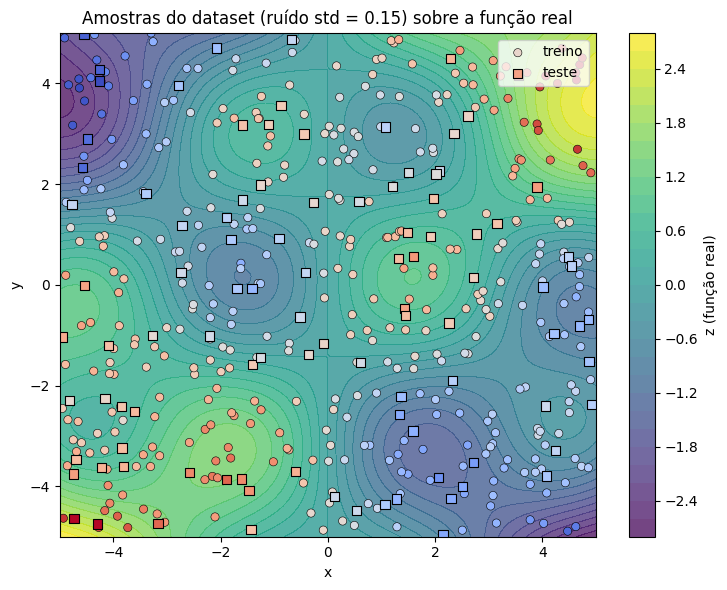

In [5]:
# Visualização: pontos amostrados sobre o contorno da função real
plt.figure(figsize=(7.5, 6))
contorno = plt.contourf(GRID_X, GRID_Y, GRID_Z_REAL, levels=30, cmap="viridis", alpha=0.75)
plt.colorbar(contorno, label="z (função real)")
plt.scatter(X_train[:, 0], X_train[:, 1], c=z_train, cmap="coolwarm",
            edgecolors="k", linewidths=0.4, s=35, label="treino")
plt.scatter(X_test[:, 0], X_test[:, 1], c=z_test, cmap="coolwarm",
            edgecolors="black", linewidths=0.8, marker="s", s=45, label="teste")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Amostras do dataset (ruído std = {RUIDO_STD}) sobre a função real")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Convertendo para Tensores PyTorch

Antes de treinar, normalizamos as entradas e a saída (padronização z-score: média 0, desvio padrão 1). Isso é importante porque a função combina termos em escalas diferentes — sem normalização, o treinamento tende a ser mais lento e instável.

As estatísticas de normalização (`média`, `desvio`) são calculadas **apenas com os dados de treino** e depois aplicadas também ao teste — evita "vazamento" de informação do teste para o treino.

In [6]:
# Estatísticas de normalização (calculadas SOMENTE no treino)
X_mean, X_std = X_train.mean(axis=0), X_train.std(axis=0)
z_mean, z_std = z_train.mean(), z_train.std()

def normalizar_X(X_bruto):
    return (X_bruto - X_mean) / X_std

def normalizar_z(z_bruto):
    return (z_bruto - z_mean) / z_std

def desnormalizar_z(z_norm):
    return z_norm * z_std + z_mean


def para_tensores(X_bruto, z_bruto=None):
    """Converte arrays NumPy (já normalizados ou não) em tensores PyTorch no device correto."""
    X_t = torch.tensor(normalizar_X(X_bruto), dtype=torch.float32).to(device)
    if z_bruto is None:
        return X_t
    z_t = torch.tensor(normalizar_z(z_bruto), dtype=torch.float32).unsqueeze(1).to(device)
    return X_t, z_t


X_train_t, z_train_t = para_tensores(X_train, z_train)
X_test_t,  z_test_t  = para_tensores(X_test, z_test)

print("Shape X_train_t:", X_train_t.shape)   # (n_treino, 2)
print("Shape z_train_t:", z_train_t.shape)   # (n_treino, 1)
print("Shape X_test_t: ", X_test_t.shape)
print("Shape z_test_t: ", z_test_t.shape)

Shape X_train_t: torch.Size([400, 2])
Shape z_train_t: torch.Size([400, 1])
Shape X_test_t:  torch.Size([100, 2])
Shape z_test_t:  torch.Size([100, 1])


## 4. Modelo Baseline

Definimos uma função `construir_modelo` flexível, que monta uma rede densa (`nn.Sequential`) a partir de:

- `hidden_layers`: lista com o número de neurônios de cada camada oculta (ex.: `[64, 64]` = duas camadas ocultas de 64 neurônios)
- `activation_name`: qual função de ativação usar entre as camadas
- `dropout`: taxa de dropout opcional (regularização)

Essa mesma função será reaproveitada em **todos os experimentos** a seguir — é o que nos permite isolar o efeito de cada componente.

In [7]:
ACTIVATIONS = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Sigmoid": nn.Sigmoid,
    "LeakyReLU": nn.LeakyReLU,
}

LOSSES = {
    "MSELoss": nn.MSELoss,
    "L1Loss (MAE)": nn.L1Loss,
    "SmoothL1Loss (Huber)": nn.SmoothL1Loss,
}


def construir_modelo(hidden_layers=(64, 64), activation_name="ReLU", dropout=0.0):
    """Monta uma rede densa (nn.Sequential): Linear -> Ativação [-> Dropout] repetido, + camada de saída linear."""
    Ativacao = ACTIVATIONS[activation_name]
    camadas = []
    in_dim = 2  # entradas: x, y
    for h in hidden_layers:
        camadas.append(nn.Linear(in_dim, h))
        camadas.append(Ativacao())
        if dropout > 0:
            camadas.append(nn.Dropout(dropout))
        in_dim = h
    camadas.append(nn.Linear(in_dim, 1))  # saída: z (regressão, sem ativação)
    return nn.Sequential(*camadas)


def construir_otimizador(nome, parametros, lr):
    if nome == "SGD":
        return torch.optim.SGD(parametros, lr=lr)
    if nome == "SGD_momentum":
        return torch.optim.SGD(parametros, lr=lr, momentum=0.9)
    if nome == "Adam":
        return torch.optim.Adam(parametros, lr=lr)
    if nome == "RMSprop":
        return torch.optim.RMSprop(parametros, lr=lr)
    raise ValueError(f"Otimizador desconhecido: {nome}")


# Configuração baseline
modelo_baseline = construir_modelo(hidden_layers=(64, 64), activation_name="ReLU", dropout=0.0).to(device)
print(modelo_baseline)

Sequential(
  (0): Linear(in_features=2, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)


## 5. Treinamento do Modelo Baseline

O loop de treinamento segue o padrão clássico do PyTorch: `zero_grad → forward → loss → backward → step`. Acompanhamos a perda de treino e de teste a cada algumas épocas para monitorar overfitting.

In [8]:
def treinar(modelo, X_train_t, z_train_t, X_test_t, z_test_t,
            loss_fn, optimizer, epochs=4000, avaliar_a_cada=20, verbose=True):
    """Loop de treinamento genérico. Retorna o histórico de perdas (treino e teste)."""
    hist_epocas, hist_train, hist_test = [], [], []

    for epoch in range(epochs):
        modelo.train()
        optimizer.zero_grad()
        pred = modelo(X_train_t)
        loss = loss_fn(pred, z_train_t)
        loss.backward()
        optimizer.step()

        if epoch % avaliar_a_cada == 0 or epoch == epochs - 1:
            modelo.eval()
            with torch.no_grad():
                test_loss = loss_fn(modelo(X_test_t), z_test_t)
            hist_epocas.append(epoch)
            hist_train.append(loss.item())
            hist_test.append(test_loss.item())

            if verbose and (epoch % (epochs // 5 or 1) == 0 or epoch == epochs - 1):
                print(f"  Época {epoch:5d} | perda treino = {loss.item():.4f} | perda teste = {test_loss.item():.4f}")

    return {"epocas": hist_epocas, "train": hist_train, "test": hist_test}


EPOCHS_BASELINE = 4000

loss_fn_baseline = nn.MSELoss()
optimizer_baseline = construir_otimizador("Adam", modelo_baseline.parameters(), lr=0.001)

print("Treinando modelo baseline...")
t0 = time.time()
historico_baseline = treinar(
    modelo_baseline, X_train_t, z_train_t, X_test_t, z_test_t,
    loss_fn_baseline, optimizer_baseline, epochs=EPOCHS_BASELINE
)
print(f"Treinamento concluído em {time.time() - t0:.1f}s")

Treinando modelo baseline...
  Época     0 | perda treino = 1.0223 | perda teste = 0.9411
  Época   800 | perda treino = 0.0218 | perda teste = 0.0401
  Época  1600 | perda treino = 0.0140 | perda teste = 0.0345
  Época  2400 | perda treino = 0.0126 | perda teste = 0.0358
  Época  3200 | perda treino = 0.0117 | perda teste = 0.0357
  Época  3999 | perda treino = 0.0108 | perda teste = 0.0355
Treinamento concluído em 2.7s


  Época  1600 | perda treino = 0.0139 | perda teste = 0.0349


  Época  2400 | perda treino = 0.0125 | perda teste = 0.0347


  Época  3200 | perda treino = 0.0117 | perda teste = 0.0350


  Época  3999 | perda treino = 0.0110 | perda teste = 0.0355
Treinamento concluído em 3.4s


## 6. Avaliação do Modelo Baseline

Calculamos três métricas de regressão no conjunto de teste (nunca visto durante o treino):

- **MSE** (Erro Quadrático Médio) — penaliza mais os erros grandes
- **R²** — proporção da variância explicada pelo modelo (quanto mais perto de 1, melhor)
- **MAPE** — erro percentual médio absoluto

In [9]:
def avaliar_modelo(modelo, X_test_t, z_test_bruto):
    """Avalia um modelo treinado no conjunto de teste, retornando MSE, R² e MAPE na escala original."""
    modelo.eval()
    with torch.no_grad():
        pred_norm = modelo(X_test_t).cpu().numpy().flatten()
    pred = desnormalizar_z(pred_norm)

    mse = mean_squared_error(z_test_bruto, pred)
    r2 = r2_score(z_test_bruto, pred)
    mape = mean_absolute_percentage_error(z_test_bruto, pred)
    return {"mse": mse, "r2": r2, "mape": mape, "pred": pred}


metricas_baseline = avaliar_modelo(modelo_baseline, X_test_t, z_test)

print("Métricas do modelo baseline (conjunto de teste):")
print(f"  MSE  = {metricas_baseline['mse']:.4f}")
print(f"  R²   = {metricas_baseline['r2']:.4f}")
print(f"  MAPE = {metricas_baseline['mape']:.4f}  ({metricas_baseline['mape']*100:.1f}%)")

Métricas do modelo baseline (conjunto de teste):
  MSE  = 0.0361
  R²   = 0.9611
  MAPE = 0.7258  (72.6%)


## 7. Visualizações: Real vs. Previsto

Quatro visualizações complementares:

1. **Curva de aprendizado** — perda de treino e teste por época
2. **Contornos lado a lado** — função real vs. função aprendida pela rede, em um grid denso
3. **Mapa de erro absoluto** — onde o modelo mais erra
4. **Dispersão real vs. previsto** — quanto mais próximo da diagonal, melhor

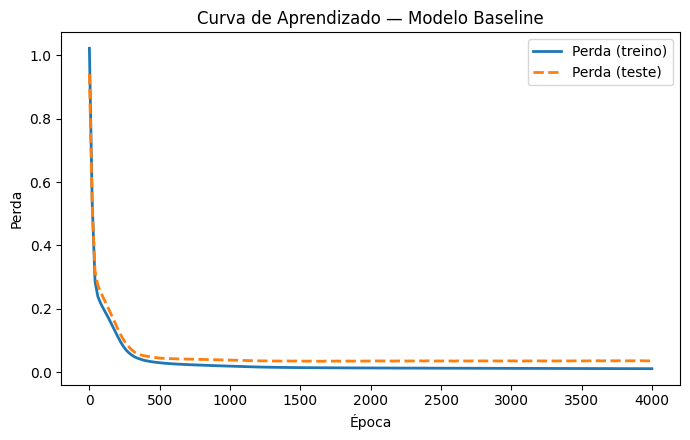

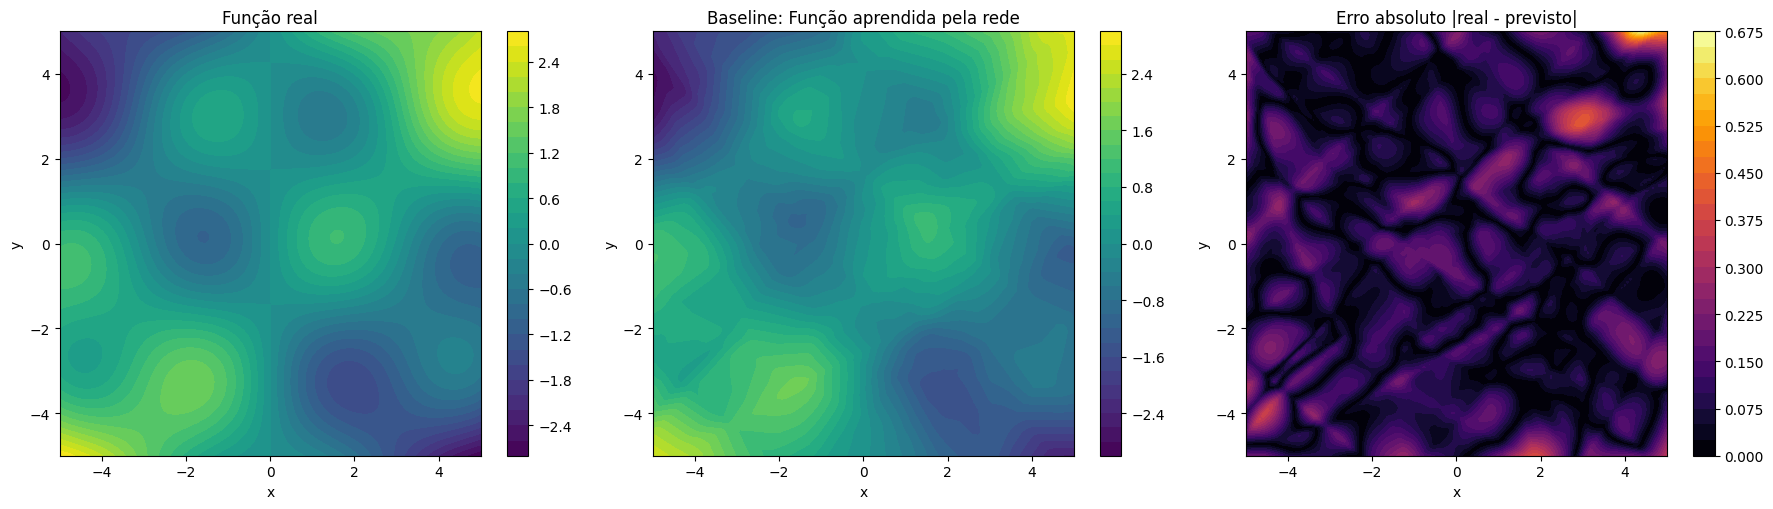

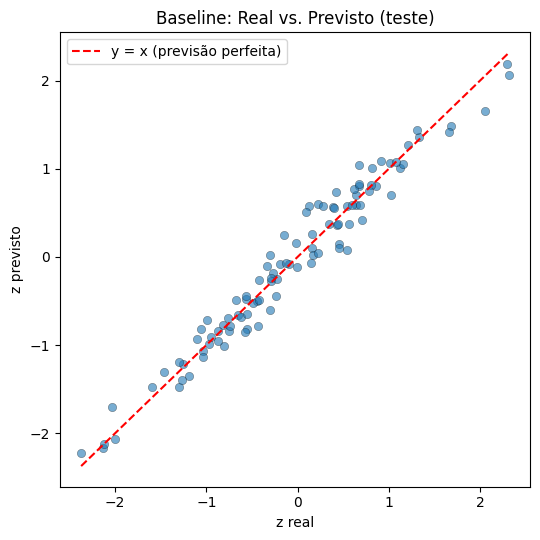

In [10]:
def prever_grid(modelo, grid_x=GRID_X, grid_y=GRID_Y):
    """Usa o modelo treinado para prever z em todos os pontos de um grid denso (para plotar contornos)."""
    pontos = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    pontos_t = para_tensores(pontos)
    modelo.eval()
    with torch.no_grad():
        pred_norm = modelo(pontos_t).cpu().numpy().flatten()
    pred = desnormalizar_z(pred_norm)
    return pred.reshape(grid_x.shape)


def plotar_curva_aprendizado(historico, titulo="Curva de Aprendizado"):
    plt.figure(figsize=(7, 4.5))
    plt.plot(historico["epocas"], historico["train"], label="Perda (treino)", linewidth=2)
    plt.plot(historico["epocas"], historico["test"], label="Perda (teste)", linewidth=2, linestyle="--")
    plt.xlabel("Época")
    plt.ylabel("Perda")
    plt.title(titulo)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plotar_comparacao_completa(modelo, z_test_bruto, pred_test, titulo_prefixo=""):
    grid_pred = prever_grid(modelo)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

    # (1) Função real
    c0 = axes[0].contourf(GRID_X, GRID_Y, GRID_Z_REAL, levels=30, cmap="viridis")
    fig.colorbar(c0, ax=axes[0])
    axes[0].set_title("Função real")
    axes[0].set_xlabel("x"); axes[0].set_ylabel("y")

    # (2) Função aprendida
    c1 = axes[1].contourf(GRID_X, GRID_Y, grid_pred, levels=30, cmap="viridis")
    fig.colorbar(c1, ax=axes[1])
    axes[1].set_title(f"{titulo_prefixo}Função aprendida pela rede")
    axes[1].set_xlabel("x"); axes[1].set_ylabel("y")

    # (3) Erro absoluto no grid
    erro_grid = np.abs(GRID_Z_REAL - grid_pred)
    c2 = axes[2].contourf(GRID_X, GRID_Y, erro_grid, levels=30, cmap="inferno")
    fig.colorbar(c2, ax=axes[2])
    axes[2].set_title("Erro absoluto |real - previsto|")
    axes[2].set_xlabel("x"); axes[2].set_ylabel("y")

    plt.tight_layout()
    plt.show()

    # (4) Dispersão real vs. previsto
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(z_test_bruto, pred_test, alpha=0.6, edgecolors="k", linewidths=0.3)
    lim_min, lim_max = min(z_test_bruto.min(), pred_test.min()), max(z_test_bruto.max(), pred_test.max())
    plt.plot([lim_min, lim_max], [lim_min, lim_max], "r--", label="y = x (previsão perfeita)")
    plt.xlabel("z real")
    plt.ylabel("z previsto")
    plt.title(f"{titulo_prefixo}Real vs. Previsto (teste)")
    plt.legend()
    plt.tight_layout()
    plt.show()


plotar_curva_aprendizado(historico_baseline, "Curva de Aprendizado — Modelo Baseline")
plotar_comparacao_completa(modelo_baseline, z_test, metricas_baseline["pred"], titulo_prefixo="Baseline: ")

## 8. Framework Genérico para os Experimentos

Para investigar a influência de cada componente da rede de forma controlada, criamos uma função única, `treinar_e_avaliar`, que:

1. Constrói o modelo a partir de uma configuração (arquitetura, ativação, dropout)
2. Treina com a função de perda, otimizador e learning rate especificados
3. Avalia no conjunto de teste (MSE, R², MAPE)
4. Devolve tudo em um dicionário — que acumulamos em uma lista (`resultados_experimentos`) para consolidar ao final

Cada experimento varia **um único fator por vez**, mantendo os demais fixos na configuração baseline — isso isola o efeito de cada componente.

In [11]:
resultados_experimentos = []  # acumula os resultados de TODOS os experimentos


def treinar_e_avaliar(nome, grupo, hidden_layers=(64, 64), activation_name="ReLU",
                       loss_name="MSELoss", lr=0.001, optimizer_name="Adam",
                       dropout=0.0, epochs=4000,
                       X_train_t=X_train_t, z_train_t=z_train_t,
                       X_test_t=X_test_t, z_test_t=z_test_t, z_test_bruto=z_test,
                       verbose=False):
    """
    Treina e avalia uma variante de modelo, registrando o resultado em `resultados_experimentos`.
    Aceita datasets customizados (usado no Experimento G, que varia o nível de ruído).
    """
    torch.manual_seed(SEED)
    modelo = construir_modelo(hidden_layers, activation_name, dropout).to(device)
    loss_fn = LOSSES[loss_name]()
    optimizer = construir_otimizador(optimizer_name, modelo.parameters(), lr)

    t0 = time.time()
    historico = treinar(modelo, X_train_t, z_train_t, X_test_t, z_test_t,
                         loss_fn, optimizer, epochs=epochs, verbose=False)
    tempo_treino = time.time() - t0

    metricas = avaliar_modelo(modelo, X_test_t, z_test_bruto)

    resultado = {
        "nome": nome, "grupo": grupo,
        "hidden_layers": str(list(hidden_layers)), "activation": activation_name,
        "loss": loss_name, "lr": lr, "optimizer": optimizer_name, "dropout": dropout,
        "mse": metricas["mse"], "r2": metricas["r2"], "mape": metricas["mape"],
        "tempo_s": tempo_treino, "historico": historico, "modelo": modelo,
    }
    resultados_experimentos.append(resultado)

    if verbose:
        print(f"  {nome:<28s} | MSE={metricas['mse']:.4f} | R²={metricas['r2']:.4f} | "
              f"MAPE={metricas['mape']*100:5.1f}% | {tempo_treino:.1f}s")
    return resultado


def plotar_barras_experimento(grupo, metrica="r2", titulo=None):
    """Gráfico de barras comparando uma métrica entre todas as variantes de um grupo de experimento."""
    dados = [r for r in resultados_experimentos if r["grupo"] == grupo]
    nomes = [r["nome"] for r in dados]
    valores = [r[metrica] for r in dados]

    plt.figure(figsize=(7.5, 4.2))
    cores = plt.cm.viridis(np.linspace(0.15, 0.85, len(nomes)))
    barras = plt.bar(nomes, valores, color=cores, edgecolor="black", linewidth=0.6)
    for barra, v in zip(barras, valores):
        plt.text(barra.get_x() + barra.get_width()/2, barra.get_height(),
                  f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    plt.ylabel(metrica.upper())
    plt.title(titulo or f"Comparação de {metrica.upper()} — {grupo}")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()


def plotar_curvas_experimento(grupo, titulo=None):
    """Sobrepõe as curvas de aprendizado (perda de teste) de todas as variantes de um grupo."""
    dados = [r for r in resultados_experimentos if r["grupo"] == grupo]
    plt.figure(figsize=(7.5, 4.5))
    for r in dados:
        plt.plot(r["historico"]["epocas"], r["historico"]["test"], label=r["nome"], linewidth=2)
    plt.xlabel("Época")
    plt.ylabel("Perda (teste)")
    plt.title(titulo or f"Curvas de aprendizado (teste) — {grupo}")
    plt.legend()
    plt.tight_layout()
    plt.show()


print("Framework de experimentos pronto.")

Framework de experimentos pronto.


## 9. Experimento A — Arquitetura das Camadas Ocultas

Testamos quatro arquiteturas, mantendo ativação (ReLU), loss (MSE), otimizador (Adam) e learning rate (0.001) fixos:

| Variante | Camadas ocultas | Ideia |
|---|---|---|
| Rasa | `[16]` | Capacidade mínima — risco de *underfitting* |
| Baseline | `[64, 64]` | Configuração de referência |
| Profunda | `[64, 64, 64, 64]` | Mais camadas — maior capacidade de composição |
| Larga | `[256]` | Uma camada, mas com muitos neurônios |

In [12]:
arquiteturas = {
    "Rasa [16]": (16,),
    "Baseline [64,64]": (64, 64),
    "Profunda [64x4]": (64, 64, 64, 64),
    "Larga [256]": (256,),
}

print("Experimento A — Arquitetura:")
for nome, arch in arquiteturas.items():
    treinar_e_avaliar(nome, grupo="A - Arquitetura", hidden_layers=arch, verbose=True)

Experimento A — Arquitetura:
  Rasa [16]                    | MSE=0.2202 | R²=0.7622 | MAPE=253.1% | 1.7s
  Baseline [64,64]             | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.7s
  Profunda [64x4]              | MSE=0.0359 | R²=0.9612 | MAPE=107.3% | 4.5s
  Larga [256]                  | MSE=0.0316 | R²=0.9659 | MAPE= 38.4% | 2.4s


  Baseline [64,64]             | MSE=0.0360 | R²=0.9611 | MAPE= 78.8% | 3.4s


  Profunda [64x4]              | MSE=0.0379 | R²=0.9591 | MAPE= 91.5% | 6.2s


  Larga [256]                  | MSE=0.0316 | R²=0.9659 | MAPE= 38.5% | 3.1s


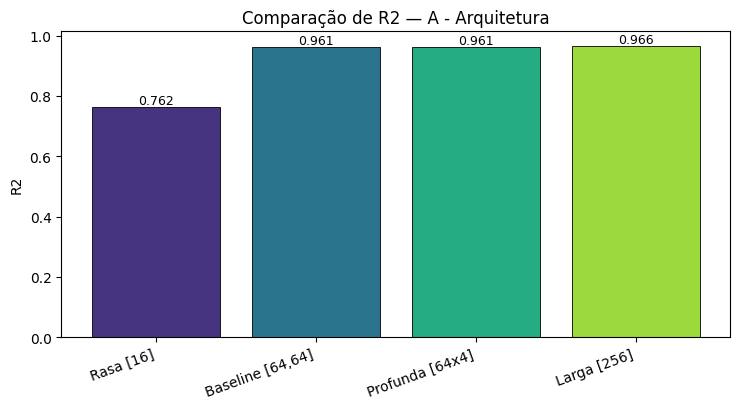

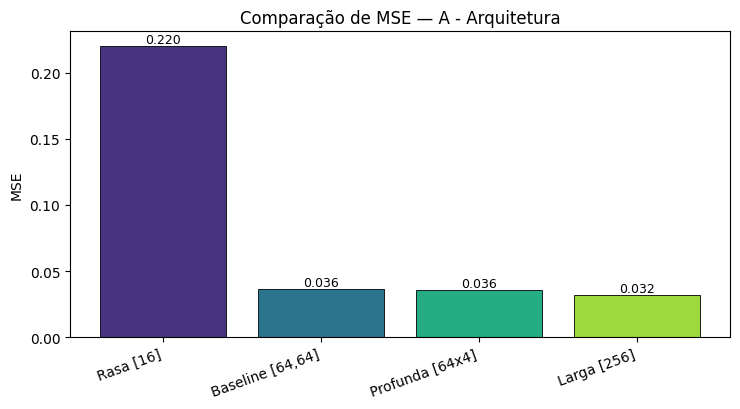

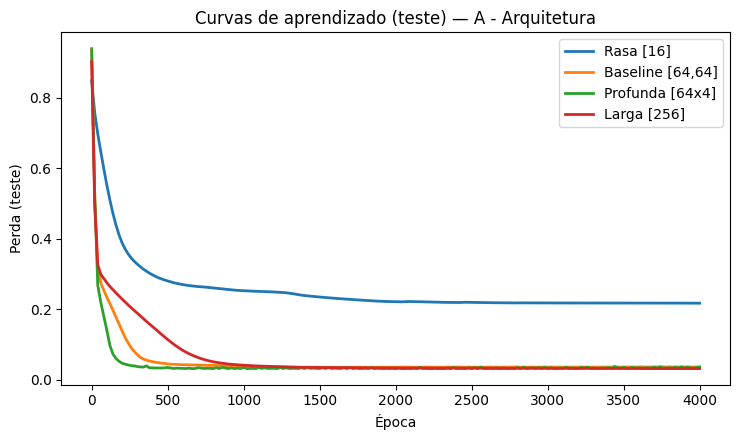

In [13]:
plotar_barras_experimento("A - Arquitetura", metrica="r2")
plotar_barras_experimento("A - Arquitetura", metrica="mse")
plotar_curvas_experimento("A - Arquitetura")

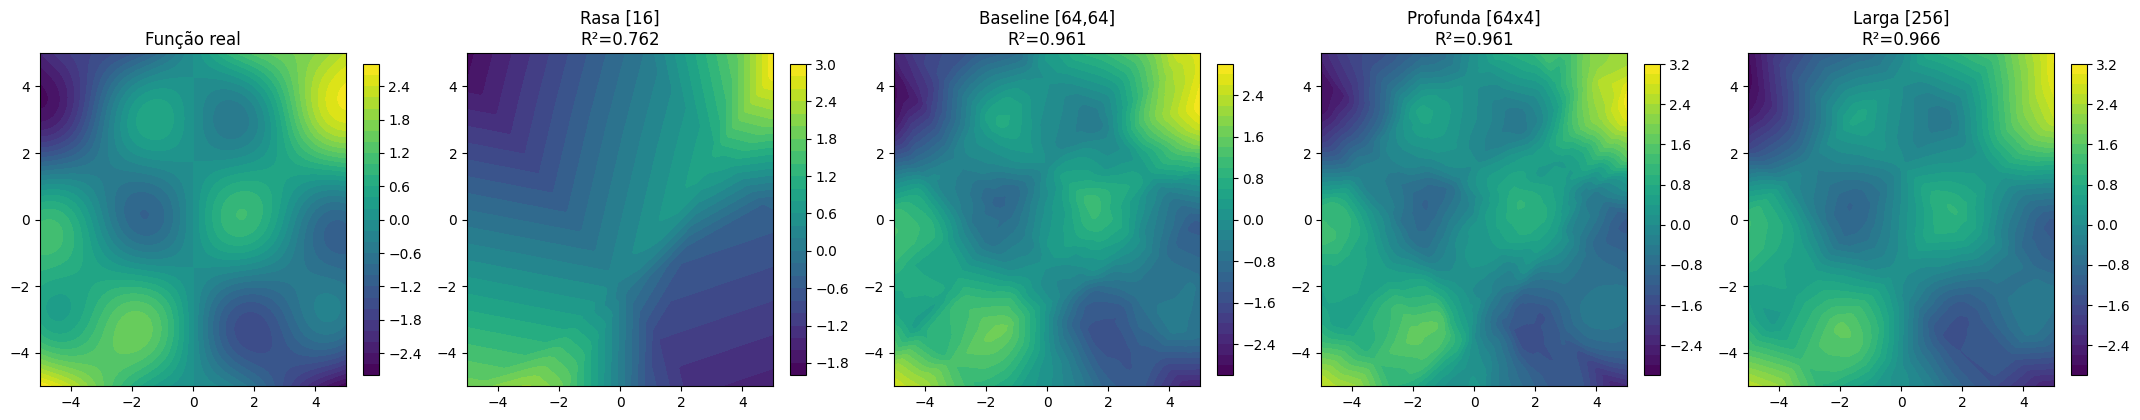

In [14]:
# Comparação visual dos contornos aprendidos por cada arquitetura
dados_a = [r for r in resultados_experimentos if r["grupo"] == "A - Arquitetura"]

fig, axes = plt.subplots(1, len(dados_a) + 1, figsize=(4.3 * (len(dados_a) + 1), 4.3))
c0 = axes[0].contourf(GRID_X, GRID_Y, GRID_Z_REAL, levels=30, cmap="viridis")
axes[0].set_title("Função real")
fig.colorbar(c0, ax=axes[0], fraction=0.046)

for ax, r in zip(axes[1:], dados_a):
    grid_pred = prever_grid(r["modelo"])
    c = ax.contourf(GRID_X, GRID_Y, grid_pred, levels=30, cmap="viridis")
    ax.set_title(f"{r['nome']}\nR²={r['r2']:.3f}")
    fig.colorbar(c, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

## 10. Experimento B — Funções de Ativação

Mantendo a arquitetura baseline `[64, 64]`, comparamos quatro funções de ativação nas camadas ocultas.

In [15]:
print("Experimento B — Ativação:")
for nome_ativ in ACTIVATIONS:
    treinar_e_avaliar(f"{nome_ativ}", grupo="B - Ativação", activation_name=nome_ativ, verbose=True)

Experimento B — Ativação:
  ReLU                         | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.7s
  Tanh                         | MSE=0.0330 | R²=0.9644 | MAPE= 68.9% | 2.8s
  Sigmoid                      | MSE=0.0477 | R²=0.9485 | MAPE=113.3% | 2.9s
  LeakyReLU                    | MSE=0.0314 | R²=0.9661 | MAPE= 69.3% | 2.8s


  Tanh                         | MSE=0.0331 | R²=0.9643 | MAPE= 69.1% | 3.8s


  Sigmoid                      | MSE=0.0459 | R²=0.9504 | MAPE=101.2% | 3.7s


  LeakyReLU                    | MSE=0.0312 | R²=0.9663 | MAPE= 71.9% | 3.3s


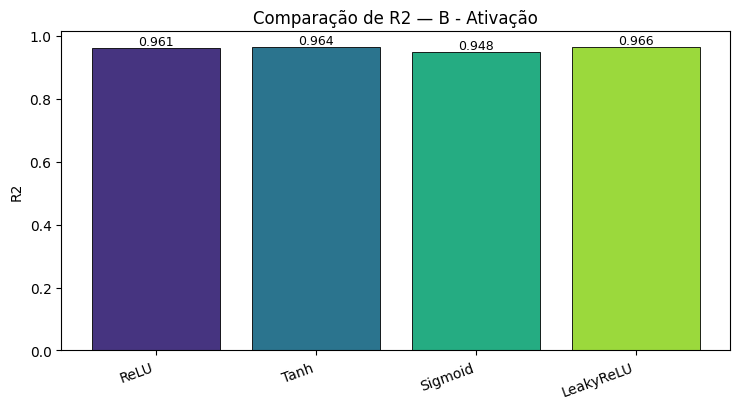

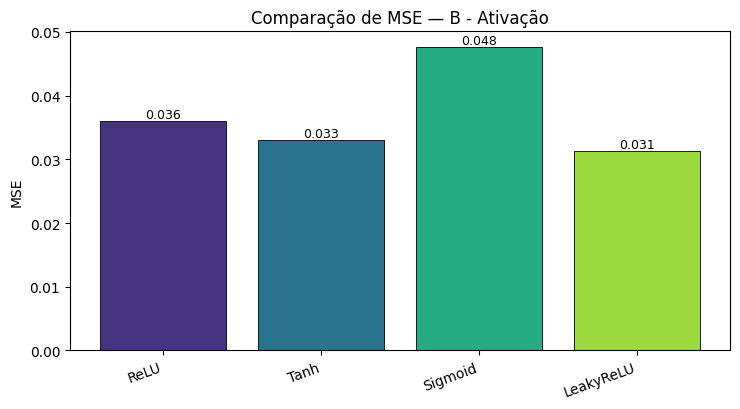

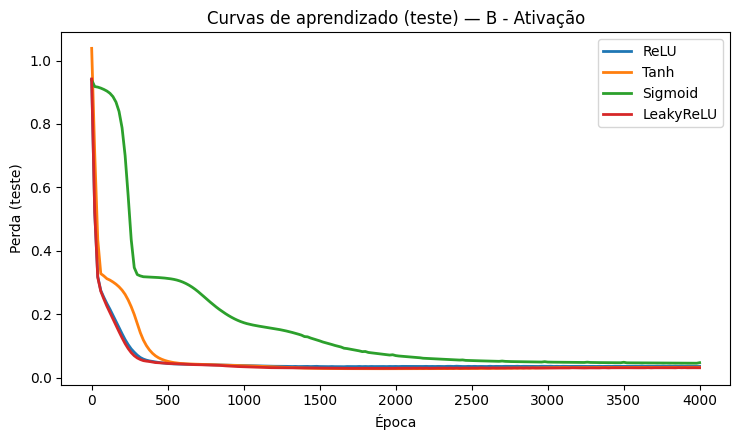

In [16]:
plotar_barras_experimento("B - Ativação", metrica="r2")
plotar_barras_experimento("B - Ativação", metrica="mse")
plotar_curvas_experimento("B - Ativação")

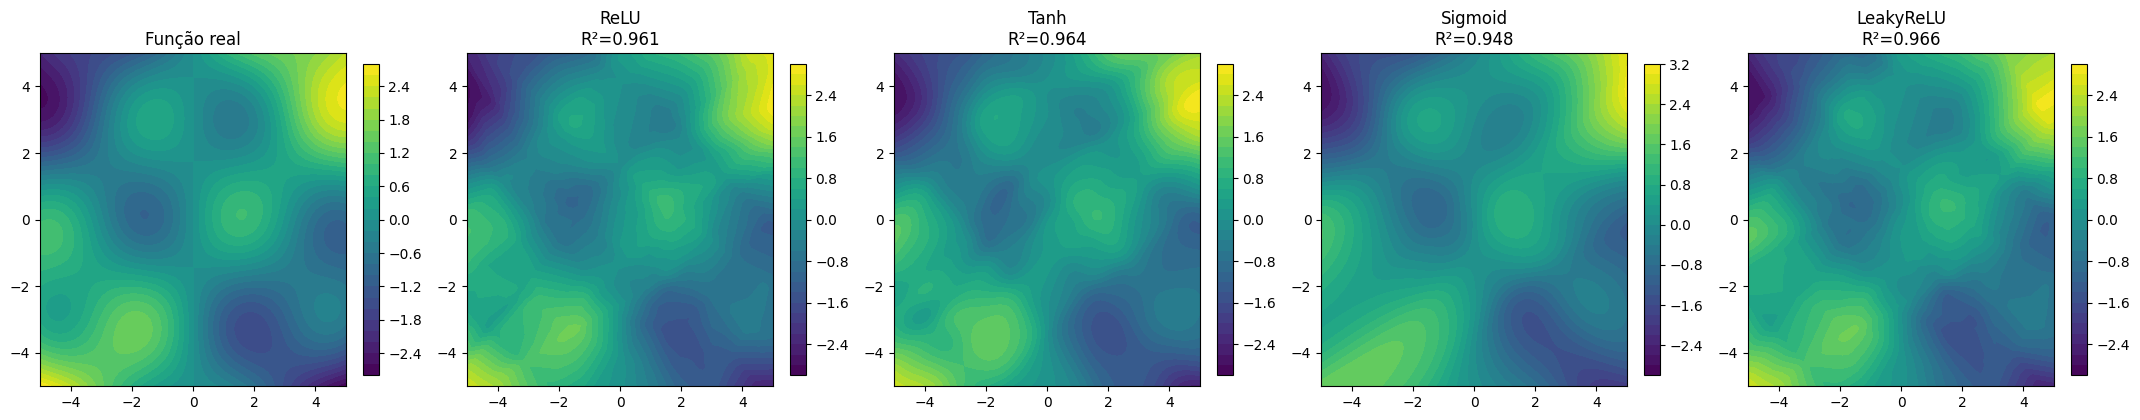

In [17]:
dados_b = [r for r in resultados_experimentos if r["grupo"] == "B - Ativação"]

fig, axes = plt.subplots(1, len(dados_b) + 1, figsize=(4.3 * (len(dados_b) + 1), 4.3))
c0 = axes[0].contourf(GRID_X, GRID_Y, GRID_Z_REAL, levels=30, cmap="viridis")
axes[0].set_title("Função real")
fig.colorbar(c0, ax=axes[0], fraction=0.046)

for ax, r in zip(axes[1:], dados_b):
    grid_pred = prever_grid(r["modelo"])
    c = ax.contourf(GRID_X, GRID_Y, grid_pred, levels=30, cmap="viridis")
    ax.set_title(f"{r['nome']}\nR²={r['r2']:.3f}")
    fig.colorbar(c, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

## 11. Experimento C — Função de Perda (*Loss Function*)

Comparamos três funções de perda para o mesmo problema de regressão:

- **MSELoss** — Erro Quadrático Médio (baseline)
- **L1Loss (MAE)** — Erro Absoluto Médio, menos sensível a outliers
- **SmoothL1Loss (Huber)** — combina MSE perto de zero e MAE longe de zero

In [18]:
print("Experimento C — Loss Function:")
for nome_loss in LOSSES:
    treinar_e_avaliar(nome_loss, grupo="C - Loss Function", loss_name=nome_loss, verbose=True)

Experimento C — Loss Function:
  MSELoss                      | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.8s
  L1Loss (MAE)                 | MSE=0.0333 | R²=0.9641 | MAPE= 51.0% | 2.8s
  SmoothL1Loss (Huber)         | MSE=0.0339 | R²=0.9634 | MAPE= 56.4% | 2.9s


  L1Loss (MAE)                 | MSE=0.0332 | R²=0.9642 | MAPE= 48.8% | 3.6s


  SmoothL1Loss (Huber)         | MSE=0.0335 | R²=0.9638 | MAPE= 46.9% | 3.6s


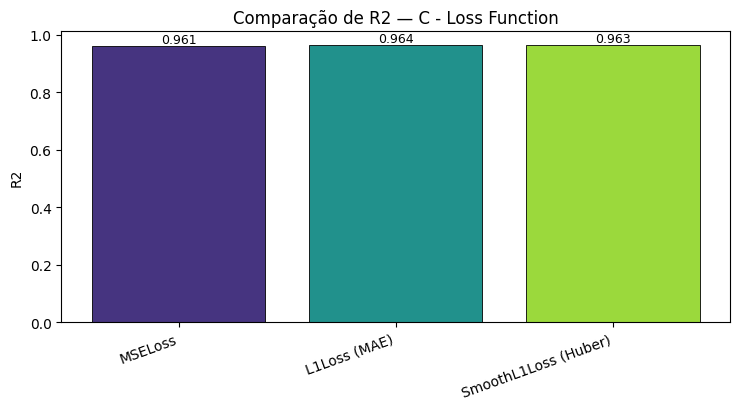

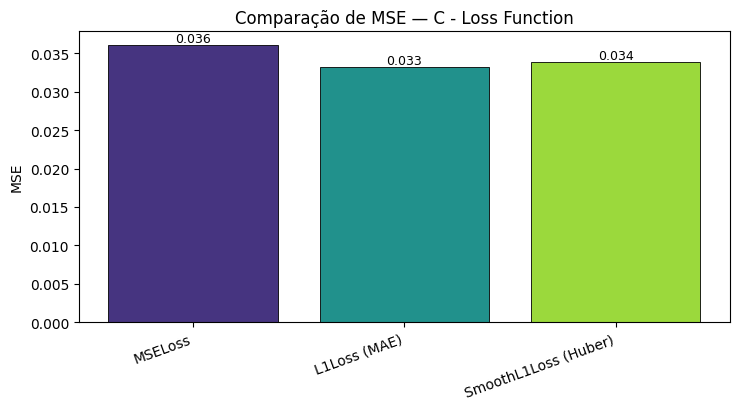

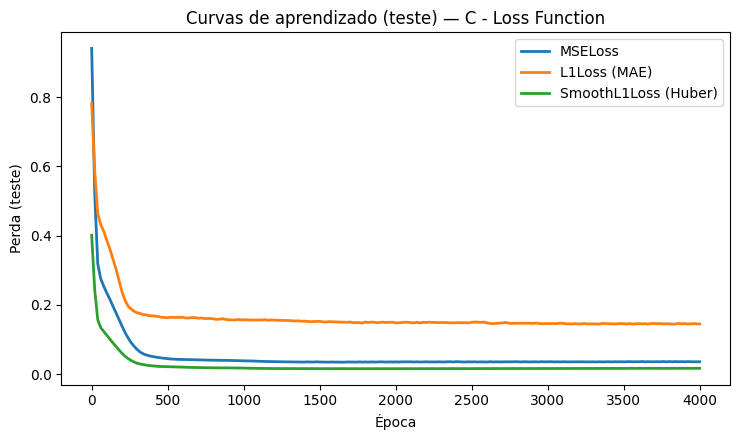

In [19]:
plotar_barras_experimento("C - Loss Function", metrica="r2")
plotar_barras_experimento("C - Loss Function", metrica="mse")
plotar_curvas_experimento("C - Loss Function")

## 12. Experimento D — Taxa de Aprendizado (*Learning Rate*)

Mantendo o otimizador Adam, testamos quatro valores de learning rate — do muito alto (risco de divergência) ao muito baixo (convergência lenta).

In [20]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]

print("Experimento D — Learning Rate:")
for lr in learning_rates:
    treinar_e_avaliar(f"lr={lr}", grupo="D - Learning Rate", lr=lr, verbose=True)

Experimento D — Learning Rate:
  lr=0.1                       | MSE=0.0344 | R²=0.9629 | MAPE= 69.3% | 2.9s
  lr=0.01                      | MSE=0.0362 | R²=0.9610 | MAPE=105.6% | 2.9s
  lr=0.001                     | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 3.0s
  lr=0.0001                    | MSE=0.0454 | R²=0.9510 | MAPE= 54.8% | 4.1s


  lr=0.01                      | MSE=0.0363 | R²=0.9608 | MAPE=103.8% | 3.9s


  lr=0.001                     | MSE=0.0360 | R²=0.9611 | MAPE= 78.8% | 3.6s


  lr=0.0001                    | MSE=0.0455 | R²=0.9508 | MAPE= 58.0% | 3.2s


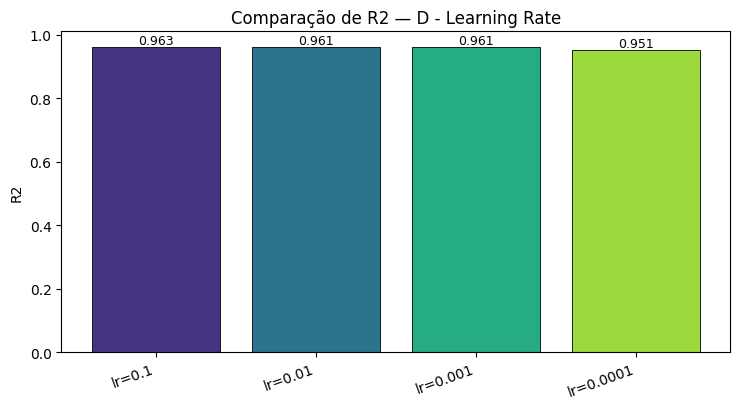

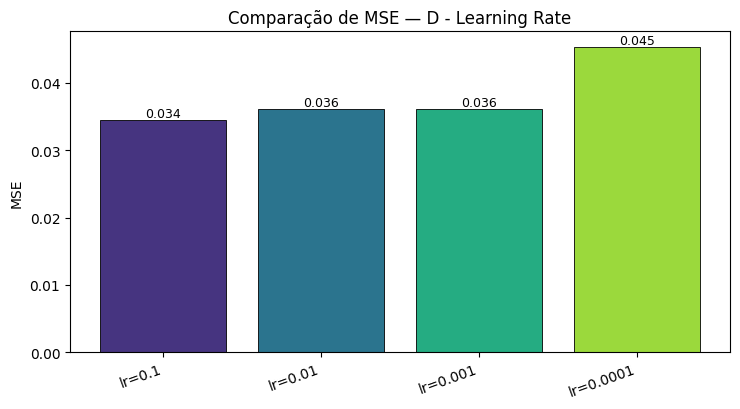

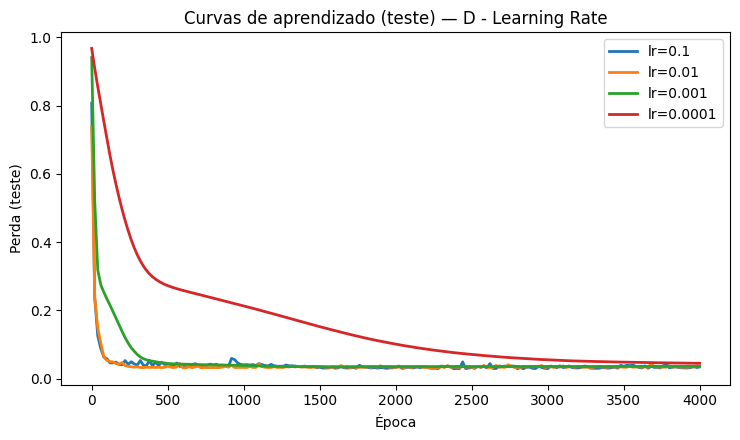

In [21]:
plotar_barras_experimento("D - Learning Rate", metrica="r2")
plotar_barras_experimento("D - Learning Rate", metrica="mse")
plotar_curvas_experimento("D - Learning Rate")

## 13. Experimento E — Otimizador

Comparamos quatro otimizadores com o mesmo learning rate (0.001) e a mesma arquitetura baseline.

In [22]:
otimizadores = ["SGD", "SGD_momentum", "Adam", "RMSprop"]

print("Experimento E — Otimizador:")
for nome_opt in otimizadores:
    # SGD puro costuma precisar de um lr maior para sair do lugar nesse problema
    lr_usado = 0.01 if nome_opt.startswith("SGD") else 0.001
    treinar_e_avaliar(f"{nome_opt} (lr={lr_usado})", grupo="E - Otimizador",
                       optimizer_name=nome_opt, lr=lr_usado, verbose=True)

Experimento E — Otimizador:
  SGD (lr=0.01)                | MSE=0.0946 | R²=0.8979 | MAPE=143.1% | 1.5s
  SGD_momentum (lr=0.01)       | MSE=0.0335 | R²=0.9638 | MAPE= 50.9% | 1.7s
  Adam (lr=0.001)              | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.2s
  RMSprop (lr=0.001)           | MSE=0.0397 | R²=0.9572 | MAPE= 56.5% | 2.1s


  SGD_momentum (lr=0.01)       | MSE=0.0336 | R²=0.9637 | MAPE= 52.0% | 2.3s


  Adam (lr=0.001)              | MSE=0.0360 | R²=0.9611 | MAPE= 78.8% | 3.5s


  RMSprop (lr=0.001)           | MSE=0.0399 | R²=0.9569 | MAPE= 56.6% | 3.0s


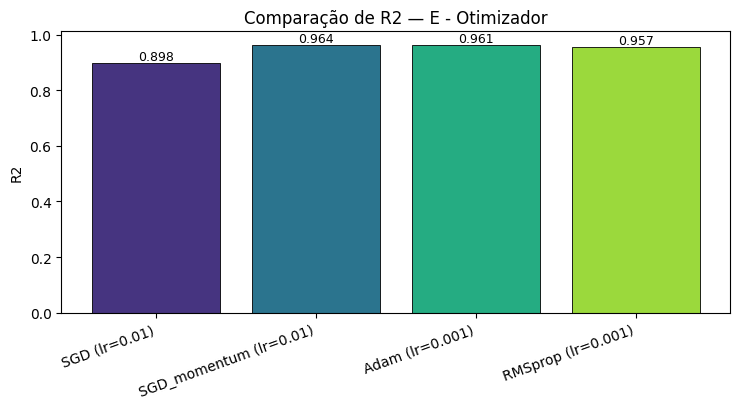

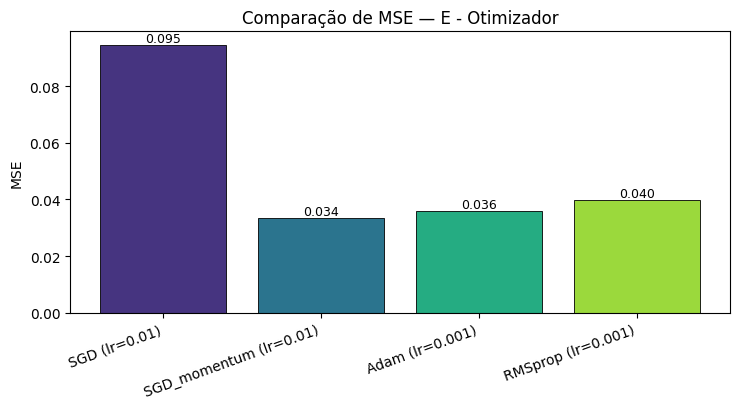

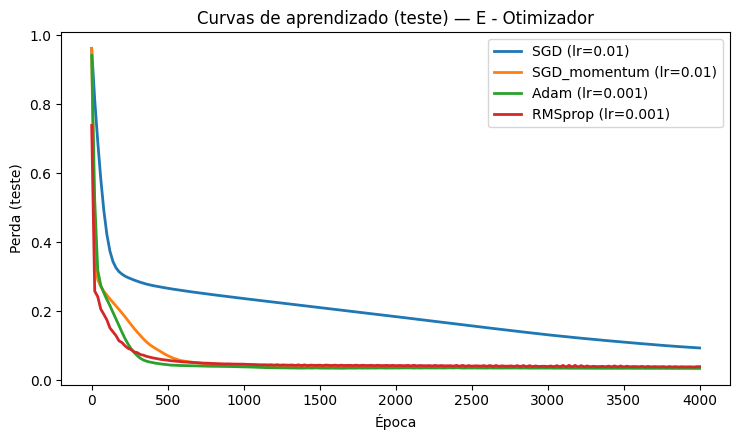

In [23]:
plotar_barras_experimento("E - Otimizador", metrica="r2")
plotar_barras_experimento("E - Otimizador", metrica="mse")
plotar_curvas_experimento("E - Otimizador")

## 14. Experimento F — Regularização (Dropout)

Testamos diferentes taxas de dropout nas camadas ocultas. Dropout tende a ajudar mais quando há overfitting — o que é mais provável com datasets pequenos e ruidosos (Experimento G explora justamente essa interação).

In [24]:
taxas_dropout = [0.0, 0.2, 0.5]

print("Experimento F — Dropout:")
for taxa in taxas_dropout:
    treinar_e_avaliar(f"dropout={taxa}", grupo="F - Dropout", dropout=taxa, verbose=True)

Experimento F — Dropout:
  dropout=0.0                  | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.1s
  dropout=0.2                  | MSE=0.0404 | R²=0.9564 | MAPE=105.9% | 3.4s
  dropout=0.5                  | MSE=0.0987 | R²=0.8934 | MAPE=157.8% | 3.6s


  dropout=0.2                  | MSE=0.0409 | R²=0.9559 | MAPE=102.6% | 6.4s


  dropout=0.5                  | MSE=0.0987 | R²=0.8935 | MAPE=155.8% | 7.4s


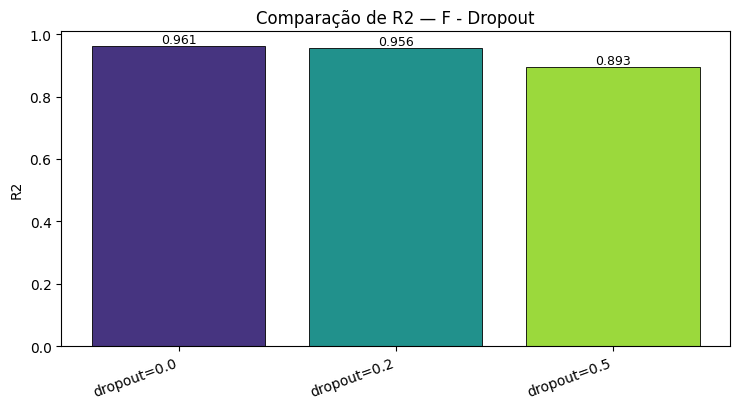

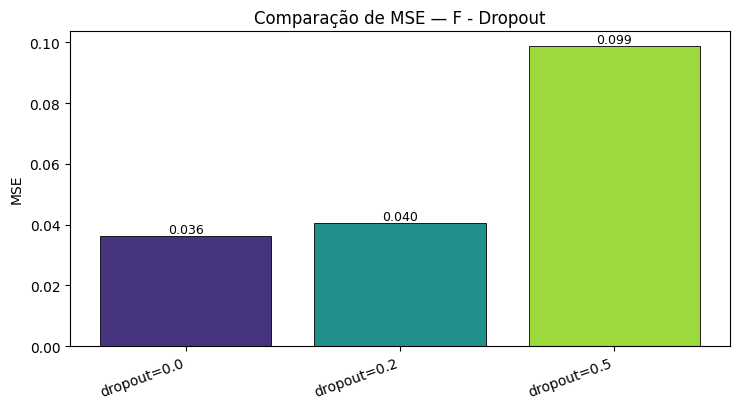

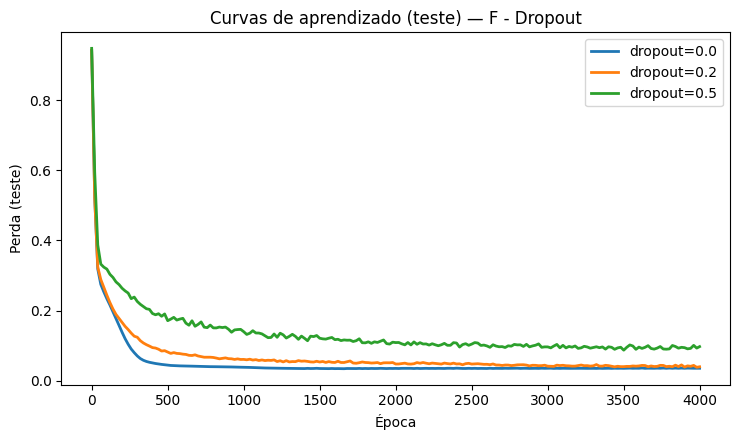

In [25]:
plotar_barras_experimento("F - Dropout", metrica="r2")
plotar_barras_experimento("F - Dropout", metrica="mse")
plotar_curvas_experimento("F - Dropout")

## 15. Experimento G — Nível de Ruído no Dataset

Por fim, avaliamos como o **nível de ruído gaussiano** nos dados de treino afeta a capacidade da rede de recuperar a função real. Para cada nível de ruído, um dataset novo é gerado e um modelo baseline é treinado do zero.

Note que aqui a métrica de teste é calculada tanto contra os **dados de teste (com ruído)** quanto contra a **função real (sem ruído)** — o segundo valor mostra o quão perto o modelo chegou da função verdadeira, mesmo quando o ruído dificulta o aprendizado.

In [26]:
niveis_ruido = [0.0, 0.15, 0.30, 0.60]
resultados_ruido_extra = []  # guarda o R² também contra a função LIMPA (sem ruído)

print("Experimento G — Nível de Ruído:")
for ruido in niveis_ruido:
    x_r, y_r, z_r, z_limpo_r = gerar_dataset(n_amostras=N_AMOSTRAS, ruido_std=ruido, seed=SEED)
    X_r = np.column_stack([x_r, y_r])
    X_tr_r, X_te_r, z_tr_r, z_te_r, z_limpo_tr_r, z_limpo_te_r = train_test_split(
        X_r, z_r, z_limpo_r, test_size=0.2, random_state=SEED
    )

    # Normalização própria deste dataset (evita vazar estatísticas entre níveis de ruído)
    Xm, Xs = X_tr_r.mean(axis=0), X_tr_r.std(axis=0)
    zm, zs = z_tr_r.mean(), z_tr_r.std()
    Xtr_t = torch.tensor((X_tr_r - Xm) / Xs, dtype=torch.float32).to(device)
    ztr_t = torch.tensor((z_tr_r - zm) / zs, dtype=torch.float32).unsqueeze(1).to(device)
    Xte_t = torch.tensor((X_te_r - Xm) / Xs, dtype=torch.float32).to(device)
    zte_t = torch.tensor((z_te_r - zm) / zs, dtype=torch.float32).unsqueeze(1).to(device)

    resultado = treinar_e_avaliar(
        f"ruído={ruido}", grupo="G - Ruído no Dataset",
        X_train_t=Xtr_t, z_train_t=ztr_t, X_test_t=Xte_t, z_test_t=zte_t,
        z_test_bruto=z_te_r, verbose=True,
    )

    # R² do modelo contra a função LIMPA (sem ruído) no conjunto de teste
    modelo = resultado["modelo"]
    modelo.eval()
    with torch.no_grad():
        pred_norm = modelo(Xte_t).cpu().numpy().flatten()
    pred_bruto = pred_norm * zs + zm
    r2_vs_limpo = r2_score(z_limpo_te_r, pred_bruto)
    resultados_ruido_extra.append({"ruido": ruido, "r2_vs_limpo": r2_vs_limpo})
    print(f"    -> R² vs. função SEM ruído: {r2_vs_limpo:.4f}")

Experimento G — Nível de Ruído:
  ruído=0.0                    | MSE=0.0037 | R²=0.9958 | MAPE= 81.8% | 2.1s
    -> R² vs. função SEM ruído: 0.9963
  ruído=0.15                   | MSE=0.0361 | R²=0.9611 | MAPE= 72.6% | 2.0s
    -> R² vs. função SEM ruído: 0.9841
  ruído=0.3                    | MSE=0.1310 | R²=0.8742 | MAPE= 99.5% | 2.0s
    -> R² vs. função SEM ruído: 0.9422
  ruído=0.6                    | MSE=0.4940 | R²=0.6517 | MAPE=153.3% | 2.1s
    -> R² vs. função SEM ruído: 0.7515


  ruído=0.15                   | MSE=0.0360 | R²=0.9611 | MAPE= 78.8% | 3.5s
    -> R² vs. função SEM ruído: 0.9832


  ruído=0.3                    | MSE=0.1300 | R²=0.8751 | MAPE= 98.2% | 3.5s
    -> R² vs. função SEM ruído: 0.9429


  ruído=0.6                    | MSE=0.4971 | R²=0.6495 | MAPE=153.7% | 3.5s
    -> R² vs. função SEM ruído: 0.7430


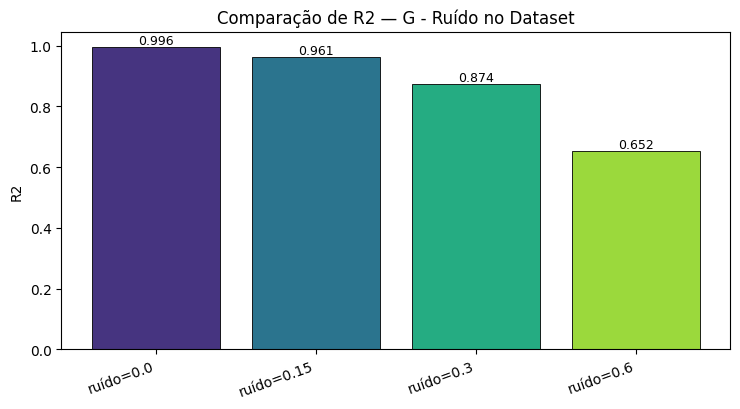

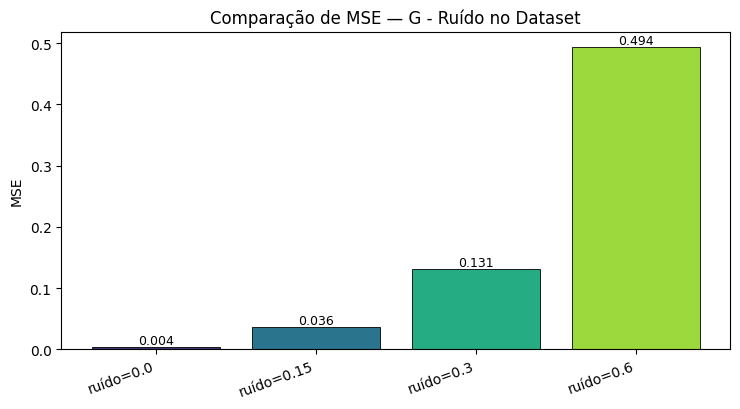

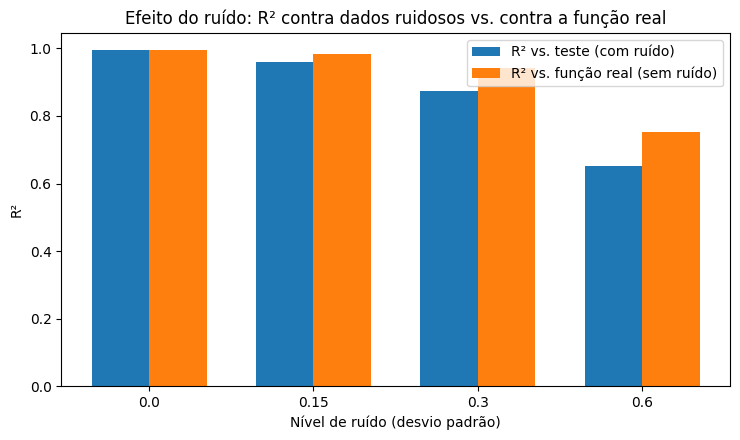

In [27]:
plotar_barras_experimento("G - Ruído no Dataset", metrica="r2")
plotar_barras_experimento("G - Ruído no Dataset", metrica="mse")

# Comparação: R² no teste (com ruído) vs. R² contra a função real (sem ruído)
dados_g = [r for r in resultados_experimentos if r["grupo"] == "G - Ruído no Dataset"]
r2_teste = [r["r2"] for r in dados_g]
r2_limpo = [d["r2_vs_limpo"] for d in resultados_ruido_extra]
labels_g = [str(n) for n in niveis_ruido]

x_pos = np.arange(len(labels_g))
largura = 0.35

plt.figure(figsize=(7.5, 4.5))
plt.bar(x_pos - largura/2, r2_teste, largura, label="R² vs. teste (com ruído)", color="#1f77b4")
plt.bar(x_pos + largura/2, r2_limpo, largura, label="R² vs. função real (sem ruído)", color="#ff7f0e")
plt.xticks(x_pos, labels_g)
plt.xlabel("Nível de ruído (desvio padrão)")
plt.ylabel("R²")
plt.title("Efeito do ruído: R² contra dados ruidosos vs. contra a função real")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Consolidação Final

Reunimos os resultados de todos os experimentos em uma única tabela para comparação direta, e destacamos a melhor configuração geral.

In [28]:
df_resultados = pd.DataFrame([
    {
        "grupo": r["grupo"], "nome": r["nome"], "hidden_layers": r["hidden_layers"],
        "activation": r["activation"], "loss": r["loss"], "lr": r["lr"],
        "optimizer": r["optimizer"], "dropout": r["dropout"],
        "MSE": r["mse"], "R2": r["r2"], "MAPE": r["mape"], "tempo_s": r["tempo_s"],
    }
    for r in resultados_experimentos
])

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
df_resultados.sort_values("R2", ascending=False).reset_index(drop=True)

,grupo,nome,hidden_layers,activation,loss,lr,optimizer,dropout,MSE,R2,MAPE,tempo_s
0,G - Ruído no Dataset,ruído=0.0,"[64, 64]",ReLU,MSELoss,0.0010,Adam,0.0000,0.0037,0.9958,0.8177,2.0682
1,B - Ativação,LeakyReLU,"[64, 64]",LeakyReLU,MSELoss,0.0010,Adam,0.0000,0.0314,0.9661,0.6935,2.8473
2,A - Arquitetura,Larga [256],[256],ReLU,MSELoss,0.0010,Adam,0.0000,0.0316,0.9659,0.3836,2.3562
3,B - Ativação,Tanh,"[64, 64]",Tanh,MSELoss,0.0010,Adam,0.0000,0.0330,0.9644,0.6890,2.7945
4,C - Loss Function,L1Loss (MAE),"[64, 64]",ReLU,L1Loss (MAE),0.0010,Adam,0.0000,0.0333,0.9641,0.5104,2.7831
5,E - Otimizador,SGD_momentum (lr=0.01),"[64, 64]",ReLU,MSELoss,0.0100,SGD_momentum,0.0000,0.0335,0.9638,0.5086,1.6969
6,C - Loss Function,SmoothL1Loss (Huber),"[64, 64]",ReLU,SmoothL1Loss (Huber),0.0010,Adam,0.0000,0.0339,0.9634,0.5641,2.8632
7,D - Learning Rate,lr=0.1,"[64, 64]",ReLU,MSELoss,0.1000,Adam,0.0000,0.0344,0.9629,0.6933,2.8676
8,A - Arquitetura,Profunda [64x4],"[64, 64, 64, 64]",ReLU,MSELoss,0.0010,Adam,0.0000,0.0359,0.9612,1.0730,4.5063
9,D - Learning Rate,lr=0.001,"[64, 64]",ReLU,MSELoss,0.0010,Adam,0.0000,0.0361,0.9611,0.7258,2.9862


In [29]:
# Melhor configuração de cada grupo de experimento
melhores_por_grupo = df_resultados.loc[df_resultados.groupby("grupo")["R2"].idxmax()]
melhores_por_grupo[["grupo", "nome", "R2", "MSE", "MAPE"]].sort_values("R2", ascending=False)

,grupo,nome,R2,MSE,MAPE
22,G - Ruído no Dataset,ruído=0.0,0.9958,0.0037,0.8177
7,B - Ativação,LeakyReLU,0.9661,0.0314,0.6935
3,A - Arquitetura,Larga [256],0.9659,0.0316,0.3836
9,C - Loss Function,L1Loss (MAE),0.9641,0.0333,0.5104
16,E - Otimizador,SGD_momentum (lr=0.01),0.9638,0.0335,0.5086
11,D - Learning Rate,lr=0.1,0.9629,0.0344,0.6933
19,F - Dropout,dropout=0.0,0.9611,0.0361,0.7258


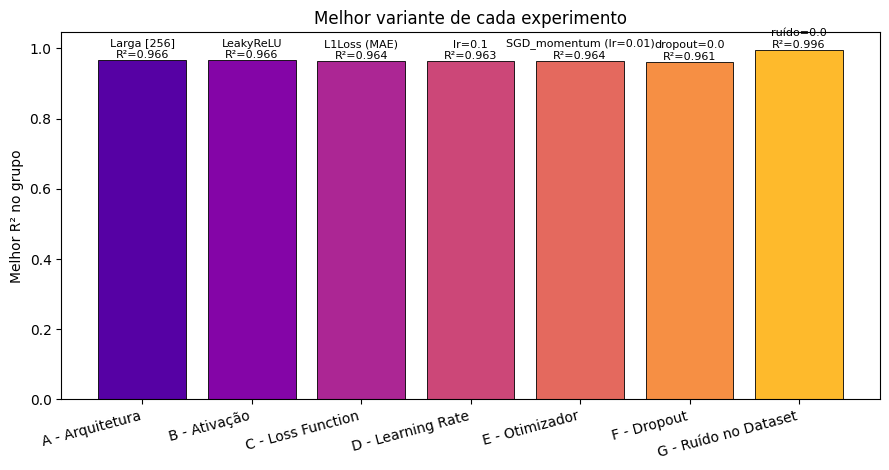

In [30]:
# Gráfico consolidado: melhor R² de cada grupo de experimento
plt.figure(figsize=(9, 4.8))
cores = plt.cm.plasma(np.linspace(0.15, 0.85, len(melhores_por_grupo)))
ordem = melhores_por_grupo.sort_values("grupo")
barras = plt.bar(ordem["grupo"], ordem["R2"], color=cores, edgecolor="black", linewidth=0.6)
for barra, (_, row) in zip(barras, ordem.iterrows()):
    plt.text(barra.get_x() + barra.get_width()/2, barra.get_height(),
              f"{row['nome']}\nR²={row['R2']:.3f}", ha="center", va="bottom", fontsize=8)
plt.ylabel("Melhor R² no grupo")
plt.title("Melhor variante de cada experimento")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Melhor modelo geral: [B - Ativação] LeakyReLU
  MSE=0.0314 | R²=0.9661 | MAPE=69.3%


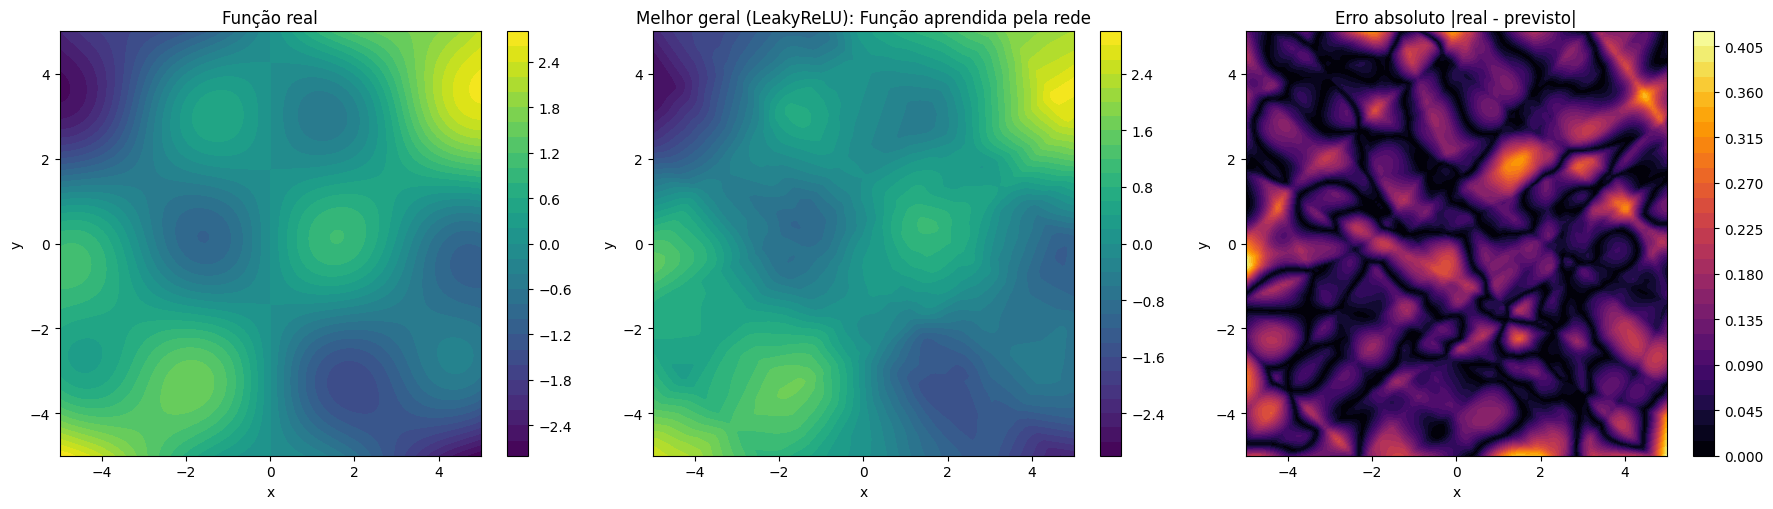

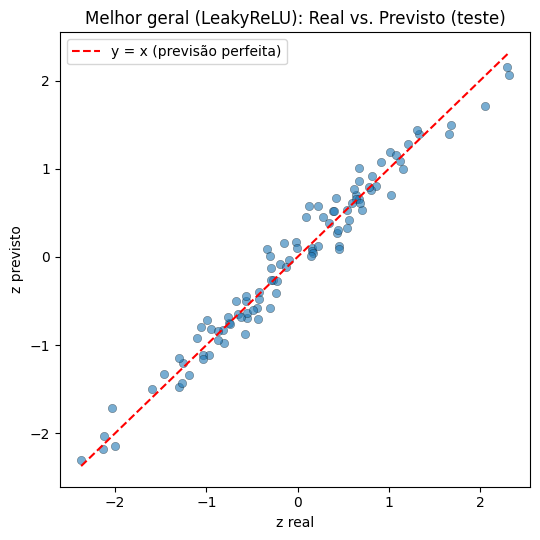

In [31]:
# Contorno do melhor modelo encontrado em TODOS os experimentos (excluindo o Experimento G,
# que usa datasets diferentes e não é diretamente comparável em MSE/R² absolutos)
df_comparavel = df_resultados[df_resultados["grupo"] != "G - Ruído no Dataset"]
idx_melhor = df_comparavel["R2"].idxmax()
melhor_geral = resultados_experimentos[idx_melhor]

print(f"Melhor modelo geral: [{melhor_geral['grupo']}] {melhor_geral['nome']}")
print(f"  MSE={melhor_geral['mse']:.4f} | R²={melhor_geral['r2']:.4f} | MAPE={melhor_geral['mape']*100:.1f}%")

metricas_melhor = avaliar_modelo(melhor_geral["modelo"], X_test_t, z_test)
plotar_comparacao_completa(
    melhor_geral["modelo"], z_test, metricas_melhor["pred"],
    titulo_prefixo=f"Melhor geral ({melhor_geral['nome']}): "
)

## 17. Conclusões

O código abaixo gera um resumo textual automático a partir dos resultados reais desta execução — os números e vencedores mudam conforme os hiperparâmetros e sementes usados, mas a estrutura do resumo permanece a mesma.

In [32]:
def resumo_grupo(grupo):
    dados = df_resultados[df_resultados["grupo"] == grupo].sort_values("R2", ascending=False)
    melhor = dados.iloc[0]
    pior = dados.iloc[-1]
    return melhor, pior

print("=" * 78)
print("RESUMO DOS EXPERIMENTOS")
print("=" * 78)

for grupo in sorted(df_resultados["grupo"].unique()):
    melhor, pior = resumo_grupo(grupo)
    print(f"\n[{grupo}]")
    print(f"  Melhor variante: {melhor['nome']}  (R²={melhor['R2']:.4f}, MSE={melhor['MSE']:.4f})")
    print(f"  Pior variante:   {pior['nome']}  (R²={pior['R2']:.4f}, MSE={pior['MSE']:.4f})")
    print(f"  Diferença de R² entre melhor e pior variante: {melhor['R2'] - pior['R2']:.4f}")

print("\n" + "=" * 78)
print(f"Melhor modelo entre TODOS os experimentos comparáveis: "
      f"[{melhor_geral['grupo']}] {melhor_geral['nome']} (R²={melhor_geral['r2']:.4f})")
print("=" * 78)

RESUMO DOS EXPERIMENTOS

[A - Arquitetura]
  Melhor variante: Larga [256]  (R²=0.9659, MSE=0.0316)
  Pior variante:   Rasa [16]  (R²=0.7622, MSE=0.2202)
  Diferença de R² entre melhor e pior variante: 0.2036

[B - Ativação]
  Melhor variante: LeakyReLU  (R²=0.9661, MSE=0.0314)
  Pior variante:   Sigmoid  (R²=0.9485, MSE=0.0477)
  Diferença de R² entre melhor e pior variante: 0.0176

[C - Loss Function]
  Melhor variante: L1Loss (MAE)  (R²=0.9641, MSE=0.0333)
  Pior variante:   MSELoss  (R²=0.9611, MSE=0.0361)
  Diferença de R² entre melhor e pior variante: 0.0030

[D - Learning Rate]
  Melhor variante: lr=0.1  (R²=0.9629, MSE=0.0344)
  Pior variante:   lr=0.0001  (R²=0.9510, MSE=0.0454)
  Diferença de R² entre melhor e pior variante: 0.0118

[E - Otimizador]
  Melhor variante: SGD_momentum (lr=0.01)  (R²=0.9638, MSE=0.0335)
  Pior variante:   SGD (lr=0.01)  (R²=0.8979, MSE=0.0946)
  Diferença de R² entre melhor e pior variante: 0.0659

[F - Dropout]
  Melhor variante: dropout=0.0  (R²=

### Principais aprendizados esperados (padrões pedagógicos gerais)

- **Arquitetura**: redes rasas demais (poucos neurônios/camadas) tendem a *underfit* a função — não conseguem capturar toda a sua curvatura. Redes muito profundas nem sempre são melhores num problema pequeno como este, e podem treinar mais devagar sem ganho real de R².
- **Ativação**: ReLU costuma convergir mais rápido; Sigmoide tende a saturar e aprender mais devagar (gradientes pequenos); Tanh fica entre os dois. LeakyReLU se comporta de forma parecida com ReLU neste problema.
- **Loss function**: MSE penaliza mais fortemente erros grandes; MAE é mais robusta a outliers, mas pode convergir de forma menos suave; Huber tenta equilibrar as duas.
- **Learning rate**: valores muito altos (ex.: 0.1) podem causar oscilação ou divergência; valores muito baixos (ex.: 0.0001) convergem de forma mais lenta e podem não atingir o mínimo no número de épocas disponível.
- **Otimizador**: Adam costuma convergir mais rápido e de forma mais estável que SGD puro neste tipo de problema; momentum ajuda o SGD a acelerar.
- **Dropout**: em um dataset pequeno e ruidoso, dropout moderado pode ajudar a generalizar; dropout excessivo pode prejudicar o ajuste (o modelo "esquece" neurônios demais durante o treino).
- **Ruído no dataset**: quanto maior o ruído, menor tende a ser o R² contra os dados de teste (que também têm ruído) — mas o R² contra a função real "limpa" costuma se manter relativamente mais alto, mostrando que a rede aprende o padrão subjacente e não apenas o ruído, especialmente com regularização adequada.

> Reexecute as células de experimento alterando os parâmetros (`RUIDO_STD`, listas de arquiteturas, learning rates, etc.) para explorar outras combinações.